# Day 13 – Unsupervised Learning: Customer Segmentation

## 1. Title
Customer segmentation using K-Means clustering on the Mall Customers dataset.

## 2. Questions
1. Load the Mall Customers dataset, including the Kaggle API workflow.
2. Inspect dataset structure, data types, summary statistics, missing values, duplicates, and unique values.
3. Clean duplicate and missing records.
4. Detect outliers with boxplots and the IQR method.
5. Encode categorical features.
6. Perform exploratory data analysis using histograms, distribution plots, countplots, boxplots, scatterplots, pairplots, and heatmaps.
7. Select useful features and remove unnecessary identifier columns.
8. Perform feature engineering and feature scaling.
9. Use the Elbow Method and silhouette score to help choose a cluster count.
10. Train K-Means and assign cluster labels.
11. Visualize customer clusters and use PCA to project data to two dimensions.
12. Interpret the customer groups.

First 5 rows:
   CustomerID  Age  AnnualIncome  SpendingScore
0           1   19            15             39
1           2   21            15             81
2           3   20            16              6
3           4   23            16             77
4           5   31            17             40

Dataset shape:
(100, 4)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   CustomerID     100 non-null    int64
 1   Age            100 non-null    int64
 2   AnnualIncome   100 non-null    int64
 3   SpendingScore  100 non-null    int64
dtypes: int64(4)
memory usage: 3.3 KB

Statistical summary:
       CustomerID         Age  AnnualIncome  SpendingScore
count  100.000000  100.000000    100.000000      100.00000
mean    50.500000   39.780000     57.230000       51.63000
std     29.011492   15.591101     34.281619       22.54363


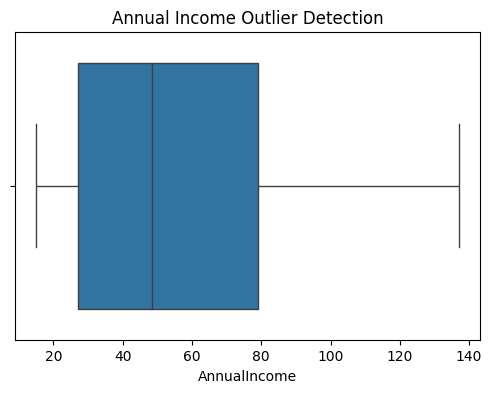

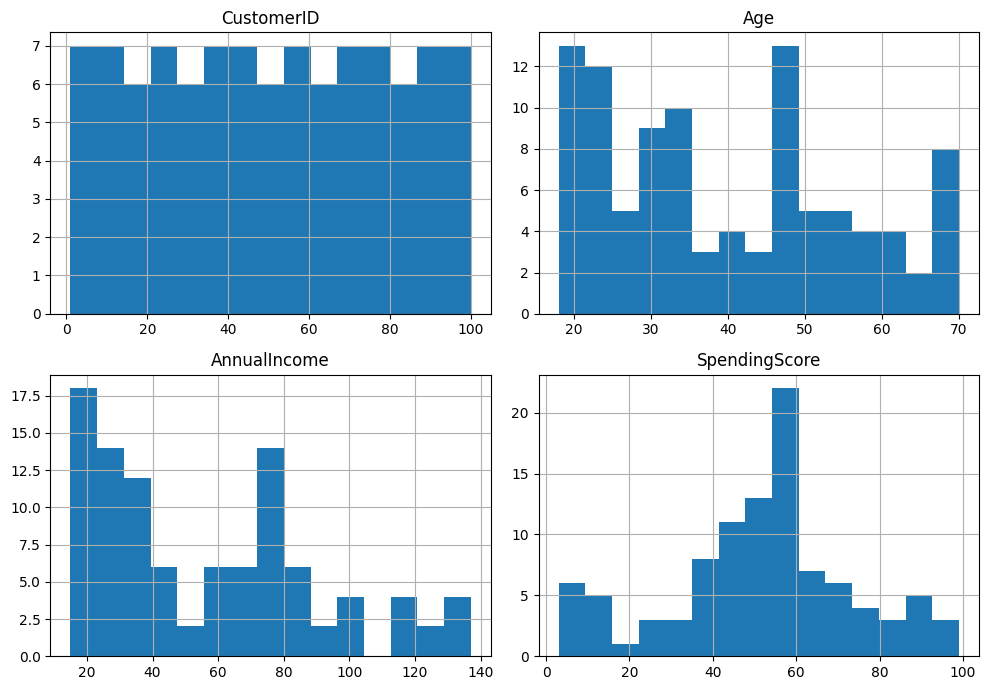

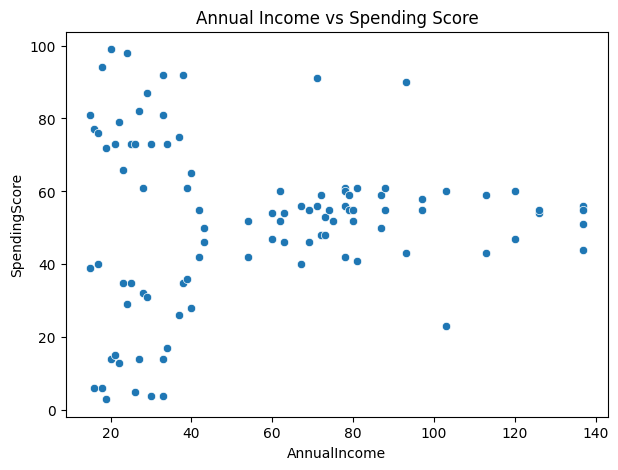

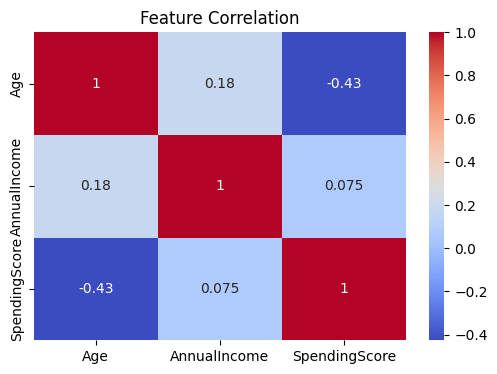

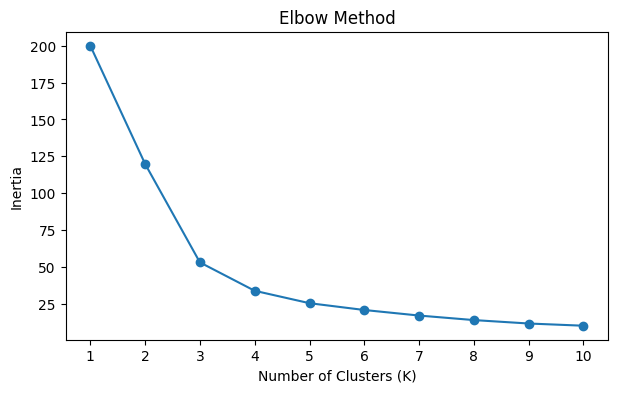


Silhouette scores:
K = 2: 0.432
K = 3: 0.556
K = 4: 0.528
K = 5: 0.534
K = 6: 0.545
K = 7: 0.529
K = 8: 0.463
K = 9: 0.472
K = 10: 0.442

Customers in each cluster:
Cluster
0    24
1    36
2    12
3    12
4    16
Name: count, dtype: int64


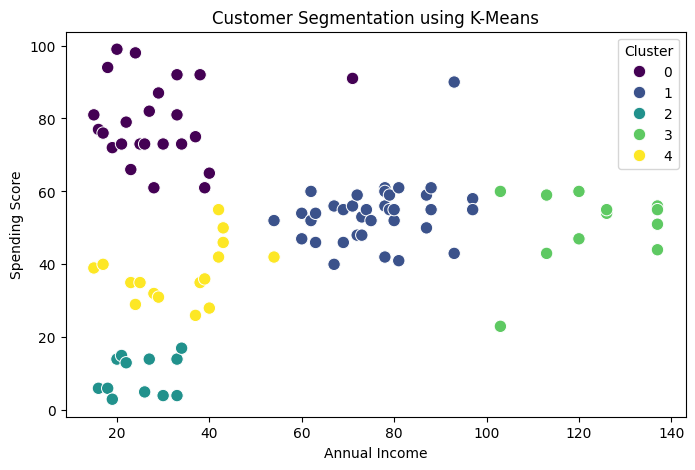

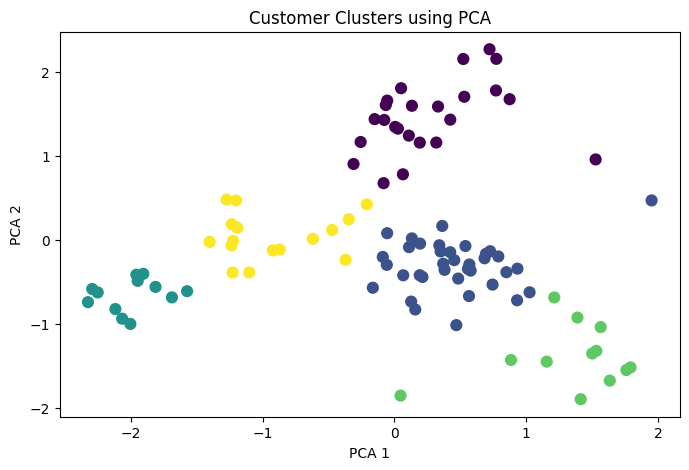


PCA explained variance: 1.0

Average characteristics of each cluster:
           Age  AnnualIncome  SpendingScore
Cluster                                    
0        26.71         28.54          78.92
1        45.89         75.78          54.06
2        48.75         24.92           9.58
3        38.25        122.67          50.58
4        40.06         33.69          37.56

Clustered dataset saved successfully!


In [5]:


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# 2. Load dataset
df = pd.read_csv("Mall_Customers.csv")

# 3. Inspect dataset
print("First 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# 4. Remove duplicates
df = df.drop_duplicates().copy()

# 5. Handle missing values
for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include=["object", "category"]).columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

# 6. Detect outliers using IQR
column = "AnnualIncome"

Q1 = df[column].quantile(0.25)
Q3 = df[column].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df[column] < lower_bound) |
    (df[column] > upper_bound)
]

print("\nNumber of income outliers:", len(outliers))

# Visualize outliers
plt.figure(figsize=(6, 4))
sns.boxplot(x=df["AnnualIncome"])
plt.title("Annual Income Outlier Detection")
plt.show()

# 7. Exploratory data analysis
df.hist(figsize=(10, 7), bins=15)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df,
    x="AnnualIncome",
    y="SpendingScore"
)
plt.title("Annual Income vs Spending Score")
plt.show()

plt.figure(figsize=(6, 4))
sns.heatmap(
    df[["Age", "AnnualIncome", "SpendingScore"]].corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Feature Correlation")
plt.show()

# 8. Select features for clustering
# CustomerID is an identifier, so exclude it.
features = df[[
    "AnnualIncome",
    "SpendingScore"
]]

# 9. Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

# 10. Elbow Method
inertia = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.show()

# 11. Silhouette scores
print("\nSilhouette scores:")

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print(f"K = {k}: {score:.3f}")

# 12. Train K-Means with 5 clusters
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("\nCustomers in each cluster:")
print(df["Cluster"].value_counts().sort_index())

# 13. Visualize clusters
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="AnnualIncome",
    y="SpendingScore",
    hue="Cluster",
    palette="viridis",
    s=80
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.show()

# 14. PCA visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["Cluster"],
    cmap="viridis",
    s=60
)

plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Customer Clusters using PCA")
plt.show()

print(
    "\nPCA explained variance:",
    round(pca.explained_variance_ratio_.sum(), 3)
)

# 15. Interpret clusters
print("\nAverage characteristics of each cluster:")

print(
    df.groupby("Cluster")[
        ["Age", "AnnualIncome", "SpendingScore"]
    ].mean().round(2)
)

# 16. Save clustered dataset
df.to_csv("Mall_Customers_Clustered.csv", index=False)

print("\nClustered dataset saved successfully!")
